In [112]:
import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.fft import fft, fftfreq
from pathlib import Path
from utils import data_loader_utils

### Initial data visualization / validation of format

In [54]:
# Path for main dataset data folder
data_path = Path("./data").absolute()
# List of all h5 files in the data folder
file_list = data_loader_utils.find_all_h5s_in_dir(data_path)

In [55]:
# Test - Reading and formatting first file
file_df = data_loader_utils.format_file(file_list[0])
file_df

,X,Y,Z,timestamp,label,machine,process,i,window
0,-15.0,25.0,-1013.0,0.0,True,1,2,13,0
1,-21.0,19.0,-1013.0,0.5,True,1,2,13,0
2,-17.0,29.0,-1013.0,1.0,True,1,2,13,0
3,-13.0,13.0,-1013.0,1.5,True,1,2,13,0
4,-9.0,25.0,-1020.0,2.0,True,1,2,13,0
...,...,...,...,...,...,...,...,...,...
94203,0.0,23.0,-1013.0,47101.5,True,1,2,13,23
94204,-19.0,11.0,-1018.0,47102.0,True,1,2,13,23
94205,-1.0,31.0,-1015.0,47102.5,True,1,2,13,23
94206,-19.0,9.0,-1020.0,47103.0,True,1,2,13,23


### Data window standardization

In [85]:
window_size = 4000
windows = []

with h5py.File(file_list[0], 'r') as f:
    dataset = f['vibration_data'][:]
    num_windows = len(dataset) // window_size
    for i in range(0, num_windows):
        w = dataset[i * window_size: (i + 1) * window_size]
        windows.append(w.transpose())

print(windows[0])

[[  -15.   -21.   -17. ...    27.    21.     0.]
 [   25.    19.    29. ...   -81.   -50.    54.]
 [-1013. -1013. -1013. ... -1110. -1128. -1100.]]


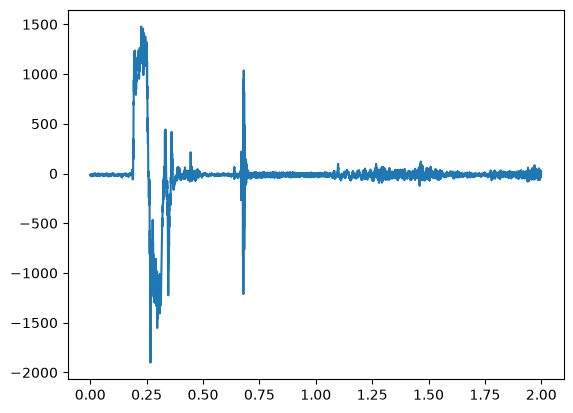

In [ ]:
%matplotlib inline

sr = 4000 # 2kHz Sample Rate over 2s
ts = 2 / sr
t = np.arange(0,2,ts)

plt.plot(t, windows[0][0])
plt.show()

In [ ]:
from scipy.signal import find_peaks

N = len(windows[0][0])

X_yf = fft(windows[0][0])
X_xf = fftfreq(N, 2 / ts)[:N // 2]
Xamp = 2.0 / N * np.abs(X_yf[0:N // 2])

freq_peaks, _ = find_peaks(Xamp, height=0.1, distance=10) # Spectral peaks
dom_Xfreq = X_xf[freq_peaks]

print(f"Dominant frequencies: {dom_Xfreq} Hz; {len(dom_Xfreq)}")

Dominant frequencies: [6.250000e-07 2.062500e-06 2.937500e-06 3.875000e-06 4.687500e-06
 5.437500e-06 6.187500e-06 7.000000e-06 7.750000e-06 9.000000e-06
 9.812500e-06 1.112500e-05 1.187500e-05 1.275000e-05 1.368750e-05
 1.437500e-05 1.518750e-05 1.593750e-05 1.656250e-05 1.718750e-05
 1.800000e-05 1.887500e-05 1.962500e-05 2.068750e-05 2.193750e-05
 2.318750e-05 2.431250e-05 2.500000e-05 2.562500e-05 2.668750e-05
 2.743750e-05 2.818750e-05 2.937500e-05 3.037500e-05 3.100000e-05
 3.206250e-05 3.318750e-05 3.393750e-05 3.462500e-05 3.537500e-05
 3.625000e-05 3.762500e-05 3.825000e-05 3.900000e-05 3.962500e-05
 4.031250e-05 4.100000e-05 4.162500e-05 4.225000e-05 4.325000e-05
 4.412500e-05 4.487500e-05 4.556250e-05 4.643750e-05 4.706250e-05
 4.775000e-05 4.868750e-05 4.931250e-05 5.000000e-05 5.081250e-05
 5.175000e-05 5.262500e-05 5.325000e-05 5.418750e-05 5.531250e-05
 5.643750e-05 5.756250e-05 5.831250e-05 5.950000e-05 6.012500e-05
 6.081250e-05 6.162500e-05 6.225000e-05 6.318750e-05 6

### Splitting training and testing buckets

In [56]:
good_file_list = [f for f in file_list if "good" in f]
bad_file_list = [f for f in file_list if "bad" in f]

In [57]:
X = np.array(good_file_list)
F = np.array(bad_file_list)
# Number of files per label
healthy = len(good_file_list)
total = len(file_list)
faulty = total - healthy
# Threshold definition
np.random.seed(42)
shuffled_indices = np.random.permutation(len(X))
test_ratio_h = 0.20 - (faulty / total)
test_set_size = int(len(X) * test_ratio_h)
# Slice indices and partition data
train_indices = shuffled_indices[test_set_size:]
test_indices = shuffled_indices[:test_set_size]

X_train, X_test = X[train_indices], np.concatenate((X[test_indices],F))
print(len(X_train), len(X_test))

1373 329


### Final data preparation for model training
Training data must be converted from Dataframe format to Numpy array format

In [58]:
for i in range(0, 1):
    df = file_df[file_df.window == i]
    A = df[["X","Y","Z"]].to_numpy()
    
A

array([[  -15.,    25., -1013.],
       [  -21.,    19., -1013.],
       [  -17.,    29., -1013.],
       ...,
       [   27.,   -81., -1110.],
       [   21.,   -50., -1128.],
       [    0.,    54., -1100.]], shape=(4000, 3))